# **What career outcomes can graduates expect in Singapore, based on their degree choice and gender?**

- # How do different degrees influence salary outcomes and extra benefits?
- # How does gender affect employment rates?
- # How does gender shape work‑life balance through differences in working hours?


## 1. Importing Files, Modules and Packages

### 1.1 Importing Necessary Resources

In [160]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### 1.2 Importing Files

In [161]:
# Load CA2 dataset 1
ca2_df1 = pd.read_csv(r"C:\Users\yanmy\Downloads\CA2 Datasets\CA2 Datasets\(1) graduate employment survey modified.csv")
ca2_df1.head()

,year,university,school,degree,Key
0,2013,Nanyang Technological University,College of Business (Nanyang Business School),Accountancy and Business,1
1,2013,Nanyang Technological University,College of Business (Nanyang Business School),Accountancy (3-yr direct Honours Programme),2
2,2013,Nanyang Technological University,College of Business (Nanyang Business School),Business (3-yr direct Honours Programme),3
3,2013,Nanyang Technological University,College of Business (Nanyang Business School),Business and Computing,4
4,2013,Nanyang Technological University,College of Engineering,Aerospace Engineering,5


In [162]:
# Load CA2 dataset 2
ca2_df2 = pd.read_csv(r"C:\Users\yanmy\Downloads\CA2 Datasets\CA2 Datasets\(2) graduate employment survey modified .csv")
ca2_df2.head()

,employment_rate_overall,employment_rate_ft_perm,basic_monthly_mean,basic_monthly_median,gross_monthly_mean,gross_monthly_median,gross_mthly_25_percentile,gross_mthly_75_percentile,gross_monthly_mean.1,gross_monthly_median.1,...,Unnamed: 38,Unnamed: 39,Unnamed: 40,Unnamed: 41,Unnamed: 42,Unnamed: 43,Unnamed: 44,Unnamed: 45,Unnamed: 46,Key
0,97.4,96.1,3701,3200,3727,3350,2900,4000,3727,3350,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
1,97.1,95.7,2850,2700,2938,2700,2700,2900,2938,2700,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
2,90.9,85.7,3053,3000,3214,3000,2700,3500,3214,3000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3
3,87.5,87.5,3557,3400,3615,3400,3000,4100,3615,3400,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4
4,95.3,95.3,3494,3500,3536,3500,3100,3816,3536,3500,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5


In [163]:
# Load MoM dataset
mom_df = pd.read_excel(r"C:\Users\yanmy\Downloads\Copy of LFR2023_SectionF.xlsx",sheet_name="F8", skiprows=6, header=0)
mom_df.head()

,Unnamed: 0,Total,Unnamed: 2,Unnamed: 3,Full-Time,Unnamed: 5,Unnamed: 6,Part-Time,Unnamed: 8,Unnamed: 9
0,NaN,Total,Male,Female,Total,Male,Female,Total,Male,Female
1,2013,45.3,47.5,42.6,48,49.4,46.2,21.5,22,21.3
2,2014,44.3,46.4,41.8,47.1,48.4,45.3,21.3,21.5,21.2
3,2015,44.2,46.5,41.7,47,48.3,45.4,21.1,21.7,20.7
4,2016,43.4,45.4,41.1,46.1,47.3,44.6,21.3,21.9,20.9


In [164]:
# Load external dataset
external_df = pd.read_csv(r"C:\Users\yanmy\Downloads\EmploymentRateofResidentsAged25to64bySex.csv")
external_df.head()

,year,sex,emp_rate
0,1991,male,90.9
1,1991,female,50.8
2,1992,male,90.0
3,1992,female,51.9
4,1993,male,90.3


In [165]:
print(ca2_df1.info())
print(ca2_df2.info())
print(mom_df.info())
print(external_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5135 entries, 0 to 5134
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   year        5135 non-null   object
 1   university  5135 non-null   object
 2   school      5135 non-null   object
 3   degree      5135 non-null   object
 4   Key         5135 non-null   int64 
dtypes: int64(1), object(4)
memory usage: 200.7+ KB
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5135 entries, 0 to 5134
Data columns (total 48 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   employment_rate_overall      5027 non-null   object 
 1   employment_rate_ft_perm      5027 non-null   object 
 2   basic_monthly_mean           5027 non-null   object 
 3   basic_monthly_median         5027 non-null   object 
 4   gross_monthly_mean           5027 non-null   object 
 5   gross_monthly_median         5027 non-n

- **Missing Values**  
  - In the employment and salary outcomes dataset, several key columns (e.g., `employment_rate_overall`, `basic_monthly_mean`, `gross_monthly_median`) have around 108 missing entries out of 5135 (~2%).  
  - These gaps can affect the analysis and must be handled carefully — either through imputation, removal, or flagging — depending on the analysis goal.  
  - The summary counts dataset also shows incomplete rows, which may distort aggregate comparisons if not addressed.

- **Redundant Columns**  
  - Multiple duplicate columns exist (e.g., `gross_monthly_mean` and `gross_monthly_mean.1`), which add noise without contributing new information.  
  - A large block of `Unnamed` columns (12–46) contain no data at all and should be dropped to streamline the dataset.  
  - Removing these redundant features reduces dimensionality, improves clarity, and prevents confusion during modeling or visualization.

- **Incorrect Data Types**  
  - Many numeric-looking fields (employment rates, salaries, percentiles) are stored as `object` instead of numeric types.  
  - This prevents valid statistical operations (e.g., correlation, regression) and must be corrected by converting to `float` or `int`.  
  - In the summary counts dataset, values like `Total`, `Full-Time`, and `Part-Time` are also stored as text, requiring conversion to numeric for proper aggregation and comparison.


The inspection reveals that while the datasets are rich in employment and salary information, they suffer from missing values, redundant columns, and incorrect data types. 


## 2. Processing the Data

### 2.1 Formatting the data

After analyzing the imported datasets, it can be found that:
- Some data need to change to numerical values
- mom_df need to be reformatted.
-   ca2_df2 has some blank columns
-   ca2_df1 and ca2_df2 can be combined by using the key.
-   there are some duplicated coulumns in ca2_df2 and some rows can be duplicated in ca2_df1 and ca2_df2, if key is not included

#### 2.1.1 Converting object to numerical

In [166]:
# List of columns you want to convert
cols_to_convert = [
    "employment_rate_overall", "employment_rate_ft_perm",
    "basic_monthly_mean", "basic_monthly_median",
    "gross_monthly_mean", "gross_monthly_median",
    "gross_mthly_25_percentile", "gross_mthly_75_percentile",
    "gross_monthly_mean.1", "gross_monthly_median.1",
    "gross_mthly_25_percentile.1", "gross_mthly_75_percentile.1"
]

# Convert to numeric
for col in cols_to_convert:
    ca2_df2[col] = pd.to_numeric(ca2_df2[col], errors="coerce")

#### 2.1.2 Reformatting MOM tables

mom_df dataframe has two rows of column names and need to combine it into one.
mom_df also contains footer rows at the end. 

In [167]:
# rename each columns
mom_df.columns = [
    "Year",
    "Average", "Average_Male", "Average_Female",
    "FullTime_Average", "FullTime_Male", "FullTime_Female",
    "PartTime_Average", "PartTime_Male", "PartTime_Female"
]

#drop duplicated male/female lables
mom_df.drop(index=0, inplace=True)

#drop footers
mom_df.drop(index=12, inplace=True)
mom_df.drop(index=13, inplace=True)

In [168]:
# List of columns to convert
cols_to_convert = [
    "Average", "Average_Male", "Average_Female",
    "FullTime_Average", "FullTime_Male", "FullTime_Female",
    "PartTime_Average", "PartTime_Male", "PartTime_Female"
]

# Convert to float 
for col in cols_to_convert:
    mom_df[col] = pd.to_numeric(mom_df[col], errors="coerce")
mom_df.head()

,Year,Average,Average_Male,Average_Female,FullTime_Average,FullTime_Male,FullTime_Female,PartTime_Average,PartTime_Male,PartTime_Female
1,2013,45.3,47.5,42.6,48.0,49.4,46.2,21.5,22.0,21.3
2,2014,44.3,46.4,41.8,47.1,48.4,45.3,21.3,21.5,21.2
3,2015,44.2,46.5,41.7,47.0,48.3,45.4,21.1,21.7,20.7
4,2016,43.4,45.4,41.1,46.1,47.3,44.6,21.3,21.9,20.9
5,2017,43.2,45.1,41.0,45.9,47.0,44.6,20.6,20.9,20.5


#### 2.1.3 Dropping blank columns and rows

In [169]:
# Drop columns that are completely blank (all NaN)
ca2_df2 = ca2_df2.dropna(axis=1, how="all")

# replace text 'na' with numpy NaN values
ca2_df2 = ca2_df2.replace(["na", "NA", "NaN"], np.nan)

# Drop rows where all columns except 'Key' are NaN
ca2_df2 = ca2_df2.dropna(subset=[col for col in ca2_df2.columns if col != "Key"], how="all")

print(ca2_df2.shape)   # check new row count
ca2_df2.tail()  # confirm blank rows are gone

(4656, 13)


,employment_rate_overall,employment_rate_ft_perm,basic_monthly_mean,basic_monthly_median,gross_monthly_mean,gross_monthly_median,gross_mthly_25_percentile,gross_mthly_75_percentile,gross_monthly_mean.1,gross_monthly_median.1,gross_mthly_25_percentile.1,gross_mthly_75_percentile.1,Key
5130,100.0,90.9,378.6,372.5,386.2,380.0,350.0,400.0,386.2,380.0,350.0,400.0,5131
5131,86.5,79.8,312.2,300.0,315.0,300.0,260.0,332.0,315.0,300.0,260.0,332.0,5132
5132,87.5,83.3,325.1,320.0,326.7,320.0,280.0,378.1,326.7,320.0,280.0,378.1,5133
5133,100.0,100.0,502.3,480.0,524.6,500.0,450.0,600.0,524.6,500.0,450.0,600.0,5134
5134,100.0,100.0,532.9,500.0,561.7,554.7,475.0,640.0,561.7,554.7,475.0,640.0,5135


#### 2.1.4 Merging CA2 dataset tables using key column

ca2_df1 and ca2_df2 are related with the common "key" column. We merged the two dataframes for future analysis.

In [170]:
merged_df = pd.merge(
    ca2_df1, 
    ca2_df2, 
    on="Key",        # common column
    how="inner"      # only keep matching rows
)
merged_df.head()

,year,university,school,degree,Key,employment_rate_overall,employment_rate_ft_perm,basic_monthly_mean,basic_monthly_median,gross_monthly_mean,gross_monthly_median,gross_mthly_25_percentile,gross_mthly_75_percentile,gross_monthly_mean.1,gross_monthly_median.1,gross_mthly_25_percentile.1,gross_mthly_75_percentile.1
0,2013,Nanyang Technological University,College of Business (Nanyang Business School),Accountancy and Business,1,97.4,96.1,3701.0,3200.0,3727.0,3350.0,2900.0,4000.0,3727.0,3350.0,2900.0,4000.0
1,2013,Nanyang Technological University,College of Business (Nanyang Business School),Accountancy (3-yr direct Honours Programme),2,97.1,95.7,2850.0,2700.0,2938.0,2700.0,2700.0,2900.0,2938.0,2700.0,2700.0,2900.0
2,2013,Nanyang Technological University,College of Business (Nanyang Business School),Business (3-yr direct Honours Programme),3,90.9,85.7,3053.0,3000.0,3214.0,3000.0,2700.0,3500.0,3214.0,3000.0,2700.0,3500.0
3,2013,Nanyang Technological University,College of Business (Nanyang Business School),Business and Computing,4,87.5,87.5,3557.0,3400.0,3615.0,3400.0,3000.0,4100.0,3615.0,3400.0,3000.0,4100.0
4,2013,Nanyang Technological University,College of Engineering,Aerospace Engineering,5,95.3,95.3,3494.0,3500.0,3536.0,3500.0,3100.0,3816.0,3536.0,3500.0,3100.0,3816.0


#### 2.1.5 Droppping duplicated rows and columns

The key column is indentifier for the dataframe but some data are duplicated when we remove key column. So, we try to drop the duplicates.

In [171]:
# Drop the Key column
merged_df = merged_df.drop(columns=["Key"])
# Count how many duplicated rows exist
merged_df.duplicated().sum()

np.int64(3408)

In [172]:
# Drop duplicated rows and keep the first occurrence
ca2_df = merged_df.drop_duplicates()

In [173]:
# Checking for duplicated columns
print(ca2_df.columns)

Index(['year', 'university', 'school', 'degree', 'employment_rate_overall',
       'employment_rate_ft_perm', 'basic_monthly_mean', 'basic_monthly_median',
       'gross_monthly_mean', 'gross_monthly_median',
       'gross_mthly_25_percentile', 'gross_mthly_75_percentile',
       'gross_monthly_mean.1', 'gross_monthly_median.1',
       'gross_mthly_25_percentile.1', 'gross_mthly_75_percentile.1'],
      dtype='object')


- gross_monthly_mean.1", "gross_monthly_median.1", "gross_mthly_25_percentile.1", "gross_mthly_75_percentile.1"
- These columns are duplicated columns which needed to be dropped

In [174]:
ca2_df = ca2_df.drop(columns=["gross_monthly_mean.1", 
                                "gross_monthly_median.1", 
                                "gross_mthly_25_percentile.1", 
                                "gross_mthly_75_percentile.1"])

In [175]:
ca2_df.shape
ca2_df.info()
ca2_df.describe()

<class 'pandas.core.frame.DataFrame'>
Index: 1248 entries, 0 to 4655
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   year                       1248 non-null   object 
 1   university                 1248 non-null   object 
 2   school                     1248 non-null   object 
 3   degree                     1248 non-null   object 
 4   employment_rate_overall    1248 non-null   float64
 5   employment_rate_ft_perm    1248 non-null   float64
 6   basic_monthly_mean         1248 non-null   float64
 7   basic_monthly_median       1248 non-null   float64
 8   gross_monthly_mean         1248 non-null   float64
 9   gross_monthly_median       1248 non-null   float64
 10  gross_mthly_25_percentile  1248 non-null   float64
 11  gross_mthly_75_percentile  1248 non-null   float64
dtypes: float64(8), object(4)
memory usage: 126.8+ KB


,employment_rate_overall,employment_rate_ft_perm,basic_monthly_mean,basic_monthly_median,gross_monthly_mean,gross_monthly_median,gross_mthly_25_percentile,gross_mthly_75_percentile
count,1248.000000,1248.000000,1248.000000,1248.000000,1248.000000,1248.000000,1248.000000,1248.000000
mean,91.662500,82.149760,3455.149972,3336.309215,3565.898039,3424.334924,3110.704808,3860.554956
std,6.563716,14.367631,1042.612450,988.928711,1075.877024,1024.886097,902.133787,1214.750949
min,66.700000,14.300000,263.900000,250.000000,263.800000,250.000000,230.000000,290.000000
25%,87.875000,74.475000,3159.500000,3000.000000,3263.500000,3125.000000,2900.000000,3500.000000
50%,92.900000,85.700000,3464.500000,3400.000000,3575.500000,3500.000000,3200.000000,3825.000000
75%,96.900000,93.000000,3931.356558,3780.750000,4050.250000,3850.000000,3500.000000,4420.000000
max,100.000000,100.000000,6962.000000,6500.000000,7139.000000,6600.000000,6000.000000,9967.000000


#### Data Formatting Justification
- The two graduate datasets were merged using the `Key` column because it uniquely identifies each record
 and ensure correct alignment of graduate records.
- Dropped rows with all `na` values, as they contained no valid data and filling would distort results.

#### 2.1.6 Outliers

In [176]:
# Lambda function for IQR outlier detection
detect_outliers_iqr = lambda series: series[
    (series < series.quantile(0.25) - 1.5 * (series.quantile(0.75) - series.quantile(0.25))) |
    (series > series.quantile(0.75) + 1.5 * (series.quantile(0.75) - series.quantile(0.25)))
]

# Columns to check
ca2_cols = [
    "employment_rate_overall", "employment_rate_ft_perm",
    "basic_monthly_mean", "basic_monthly_median",
    "gross_monthly_mean", "gross_monthly_median",
    "gross_mthly_25_percentile", "gross_mthly_75_percentile"
]

mom_cols = [
    "Average", "Average_Male", "Average_Female",
    "FullTime_Average", "FullTime_Male", "FullTime_Female",
    "PartTime_Average", "PartTime_Male", "PartTime_Female"
]

external_cols = ["emp_rate"]

In [177]:
# For ca2_df1
for col in ca2_cols:
    outliers = detect_outliers_iqr(ca2_df[col])
    print(f"{col}: {len(outliers)} outliers")
    # Optional: print(outliers.values)

# For mom_df
for col in mom_cols:
    outliers = detect_outliers_iqr(mom_df[col])
    print(f"{col}: {len(outliers)} outliers")

# For external_df
for col in external_cols:
    outliers = detect_outliers_iqr(external_df[col])
    print(f"{col}: {len(outliers)} outliers")

employment_rate_overall: 22 outliers
employment_rate_ft_perm: 29 outliers
basic_monthly_mean: 126 outliers
basic_monthly_median: 132 outliers
gross_monthly_mean: 136 outliers
gross_monthly_median: 157 outliers
gross_mthly_25_percentile: 142 outliers
gross_mthly_75_percentile: 132 outliers
Average: 0 outliers
Average_Male: 0 outliers
Average_Female: 1 outliers
FullTime_Average: 0 outliers
FullTime_Male: 0 outliers
FullTime_Female: 0 outliers
PartTime_Average: 0 outliers
PartTime_Male: 0 outliers
PartTime_Female: 0 outliers
emp_rate: 0 outliers


We can find that salaries cloumns contains significant ammount of outliers.
We decided to keep the outliers in employment and salary data because salaries naturally vary a lot; some graduates earn much more or less than others and these extremes show the true range of outcomes. Keeping them makes our analysis more realistic, since removing them would hide important differences in graduate pay.

### 2.2 Scaling and Normalization

#### 2.2.1 Year Scaling

All datasets were scaled to the common period 2013–2022 to ensure comparability. WE chose this range was because it is the overlap across graduate outcomes, work hours, and employment trends. Aligning the years avoids misleading comparisons and keeps the analysis focused on a consistent timeframe. 
* Original external_df is reserved for check employment growth across time. 

In [178]:
valid_years = ["2013","2014","2015","2016","2017","2018","2019","2020","2021","2022"]

ca2_df = ca2_df[ca2_df["year"].isin(valid_years)]

mom_df = mom_df[(mom_df["Year"] >= 2013) & (mom_df["Year"] <= 2022)]
exl_scale_df = external_df[(external_df["year"] >= 2013) & (external_df["year"] <= 2022)]

#### 2.2.2 Degree Normalization

In [179]:
# Top 20 most common degrees
print(ca2_df["degree"].value_counts().head(20))

degree
Economics                                                       17
Accountancy                                                     14
Bachelor of Engineering (Mechanical Engineering)                10
Bachelor of Science (Project and Facilities Management)         10
Bachelor of Dental Surgery                                      10
Bachelor of Engineering (Civil Engineering)                     10
Bachelor of Engineering (Chemical Engineering)                  10
Bachelor of Engineering (Computer Engineering)                  10
Bachelor of Engineering (Electrical Engineering)                10
Bachelor of Engineering (Industrial and Systems Engineering)    10
Bachelor of Engineering (Environmental Engineering)             10
Bachelor of Computing (Computer Science)                        10
Bachelor of Computing (Information Systems)                     10
Bachelor of Business Administration (Accountancy) (Hons)        10
Bachelor of Business Administration (Hons)             

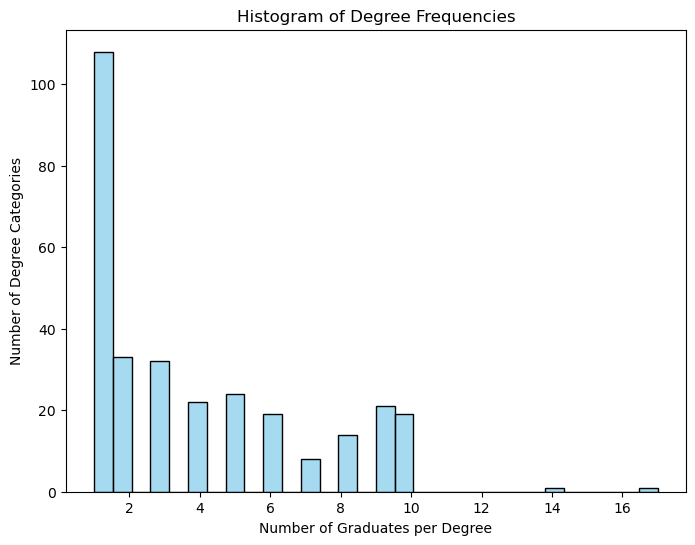

In [193]:
# Count frequency of each degree
degree_counts = ca2_df["degree"].value_counts()

# Plot histogram of degree frequencies
plt.figure(figsize=(8,6))
sns.histplot(degree_counts, bins=30, kde=False, color="skyblue")
plt.title("Histogram of Degree Frequencies")
plt.xlabel("Number of Graduates per Degree")
plt.ylabel("Number of Degree Categories")
plt.show()

The histogram of degree frequencies shows that the dataset contains a very large variety of degree categories, but most of them are represented by only a small number of graduates. The highest concentration occurs at just one graduates per degree, with over a hundred categories falling into this range, while only a handful of degrees have more than 10 graduates. This long‑tail distribution highlights that the data is highly fragmented, with many niche or specialized degrees contributing small counts, and only a few degrees having substantial representation. This insight suggests that analyzing outcomes by individual degree may be noisy, and grouping degrees into broader categories will provide clearer and more reliable comparisons.


Degree names were inconsistent due to suffixes, symbols and variations across universities. To ensure clarity, degree names should be standardized and grouped into broader categories (e.g., Engineering, Business, Law, Medicine, Computing). This grouping allows meaningful comparisons across disciplines while avoiding noise from duplicate or inconsistent labels.

In [180]:
# Lowercase everything
ca2_df["degree_clean"] = ca2_df["degree"].str.lower()

# Remove leading/trailing spaces
ca2_df["degree_clean"] = ca2_df["degree_clean"].str.strip()

# Remove symbols like ^, #, *, ( ) by replacing them with empty string
ca2_df["degree_clean"] = ca2_df["degree_clean"].str.replace(r"\^|\#|\*|\(|\)", "", regex=True)

# Standardize common suffixes
ca2_df["degree_clean"] = ca2_df["degree_clean"].str.replace("honours", "")
ca2_df["degree_clean"] = ca2_df["degree_clean"].str.replace("hons", "")

In [181]:
# dictionary of keywords for each categories

degree_map = {
    "double": "Double Degree",
    "account": "Accountancy",
    "business": "Business",
    "eco": "Economics",
    "law": "Law",
    "med": "Medicine",
    "dentistry": "Dentistry",
    "dental": "Dentistry",
    "engineer": "Engineering",
    "comput": "Computing",
    "info": "Computing",
    "data": "Computing",
    "psychology": "Social Sciences",
    "sociology": "Social Sciences",
    "art": "Arts & Humanities",
    "design": "Arts & Humanities",
    "music": "Arts & Humanities",
    "education": "Education",
    "nursing": "Health Sciences",
    "pharmacy": "Health Sciences",
    "bio": "Science",
    "chemistry": "Science",
    "physics": "Science",
    "math": "Science",
    "sport science": "Health Sciences",
    "social": "Social Sciences",
    "hospitality": "Hospitality & Tourism"
}

In [182]:
# apply for each degree

def map_category(x):
    for key, value in degree_map.items():
        if key in x:
            return value
    return "Other"

ca2_df["degree_group"] = ca2_df["degree_clean"].apply(map_category)
print(ca2_df["degree_group"].value_counts())

degree_group
Engineering              339
Other                    185
Arts & Humanities        121
Computing                 85
Business                  75
Accountancy               70
Social Sciences           54
Medicine                  53
Health Sciences           41
Economics                 39
Science                   36
Law                       30
Education                 18
Double Degree             12
Dentistry                 10
Hospitality & Tourism      2
Name: count, dtype: int64


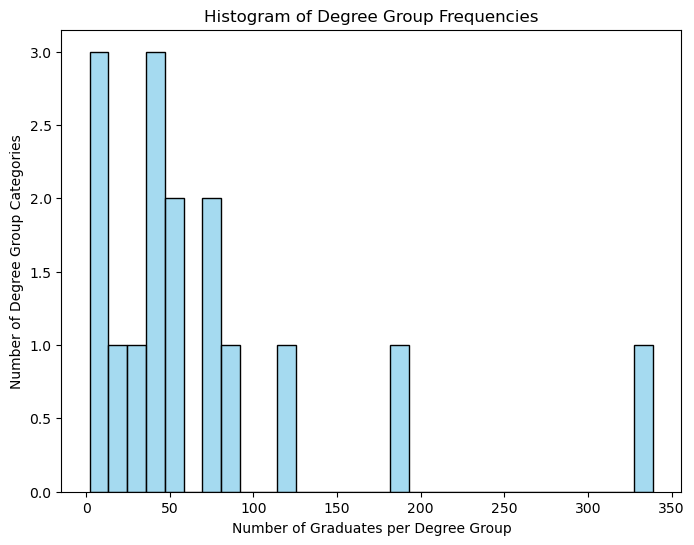

In [194]:
# Count frequency of each degree
degree_counts = ca2_df["degree_group"].value_counts()

# Plot histogram of degree group frequencies
plt.figure(figsize=(8,6))
sns.histplot(degree_counts, bins=30, kde=False, color="skyblue")
plt.title("Histogram of Degree Group Frequencies")
plt.xlabel("Number of Graduates per Degree Group")
plt.ylabel("Number of Degree Group Categories")
plt.show()

The first histogram showed many niche degrees with very few graduates, making comparisons noisy. After grouping, the second histogram reveals clearer patterns, with most fields modestly represented and a few attracting large cohorts. This step makes the data more interpretable and sets the stage for meaningful analysis of career outcomes.

**School names were kept as they are since they represent distinct institutions. Unlike degrees, we won’t be grouping or analyzing schools, so no normalization was needed.**

## 3. Data Analysis

### 3.1 Inserting Necessary Columns

As part of our analysis, we removed redundant features to keep the dataset clean and focused, and we created a new variable called extra_benefit to highlight the difference between gross and basic monthly pay, which represents allowances or bonuses beyond base salary.

In [183]:
ca2_df = ca2_df.drop(columns=["degree_clean"])

# Now create the new column
ca2_df["extra_benefit"] = ca2_df["gross_monthly_mean"] - ca2_df["basic_monthly_mean"]

# Quick check
ca2_df.head()

,year,university,school,degree,employment_rate_overall,employment_rate_ft_perm,basic_monthly_mean,basic_monthly_median,gross_monthly_mean,gross_monthly_median,gross_mthly_25_percentile,gross_mthly_75_percentile,degree_group,extra_benefit
0,2013,Nanyang Technological University,College of Business (Nanyang Business School),Accountancy and Business,97.4,96.1,3701.0,3200.0,3727.0,3350.0,2900.0,4000.0,Accountancy,26.0
1,2013,Nanyang Technological University,College of Business (Nanyang Business School),Accountancy (3-yr direct Honours Programme),97.1,95.7,2850.0,2700.0,2938.0,2700.0,2700.0,2900.0,Accountancy,88.0
2,2013,Nanyang Technological University,College of Business (Nanyang Business School),Business (3-yr direct Honours Programme),90.9,85.7,3053.0,3000.0,3214.0,3000.0,2700.0,3500.0,Business,161.0
3,2013,Nanyang Technological University,College of Business (Nanyang Business School),Business and Computing,87.5,87.5,3557.0,3400.0,3615.0,3400.0,3000.0,4100.0,Business,58.0
4,2013,Nanyang Technological University,College of Engineering,Aerospace Engineering,95.3,95.3,3494.0,3500.0,3536.0,3500.0,3100.0,3816.0,Engineering,42.0


### 3.2 Graphical Analysis

#### 3.2.1 Salary Distribution
We used a boxplot to show salary distribution by degree group because it highlights not just the average salary but also the spread, quartiles, and outliers. This makes it easier to compare how salaries vary for each degree group.


C:\Users\yanmy\AppData\Local\Temp\ipykernel_25268\416756150.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=ca2_df, x="degree_group", y="basic_monthly_mean", palette="Set2")


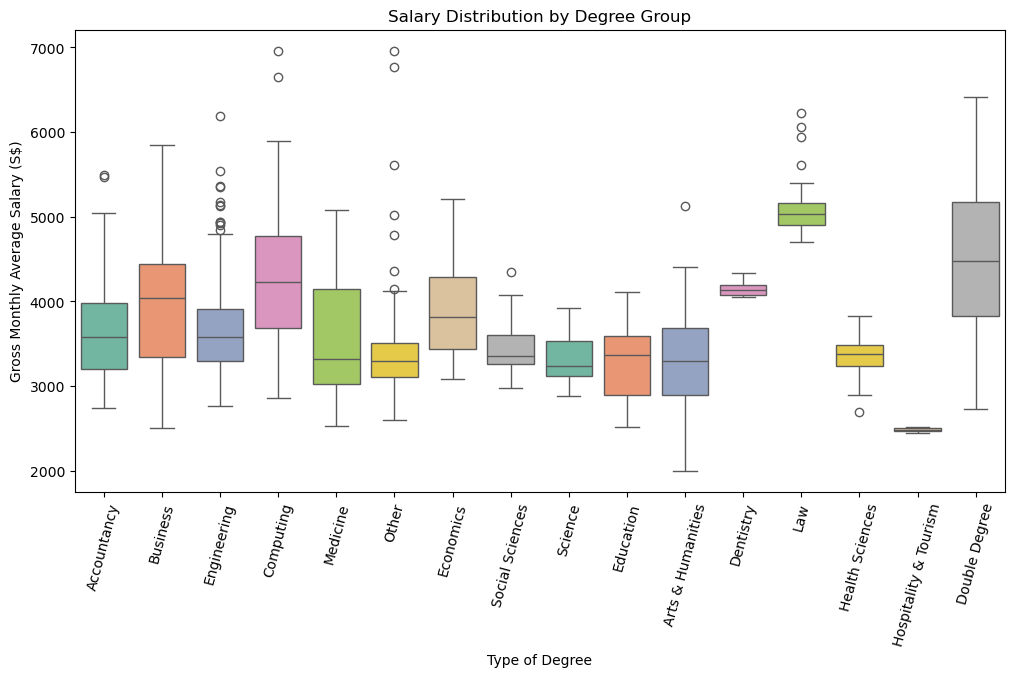

In [184]:
plt.figure(figsize=(12,6))
sns.boxplot(data=ca2_df, x="degree_group", y="basic_monthly_mean", palette="Set2")
plt.xticks(rotation=75)
plt.title("Salary Distribution by Degree Group")
plt.ylabel("Gross Monthly Average Salary (S$)")
plt.xlabel("Type of Degree")
plt.show()

#### Reflection: Salary Distribution by Degree Group
This chart shows how average salaries and their variability differ across academic fields.
Key insights:
- Law, Dentistry, and Double Degree graduates have the highest average salaries. Law, Dentistry are with relatively tight distributions.
- Hospitality & Tourism shows the lowest average salary.
- Engineering, Business, and Computing sit in the mid‑range.
- Wider distributions in some fields (e.g., Medicine, Social Sciences) indicate more variability in graduate outcomes.
- On average, a person can expect - $3500, though actual outcomes vary widely depending on the chosen degree group and the spread of salaries within each field. This shows how degree choice not only affects earning potential but also the stability and predictability of income.

#### 3.2.2 Extra Benefits

We used a bar chart to show the average extra benefits by degree group because it makes it easy to compare how different fields offer additional pay beyond base salary. This helps us see how degree choice affects overall salary packages and links directly to our study of salary, job stability, and work‑life balance.

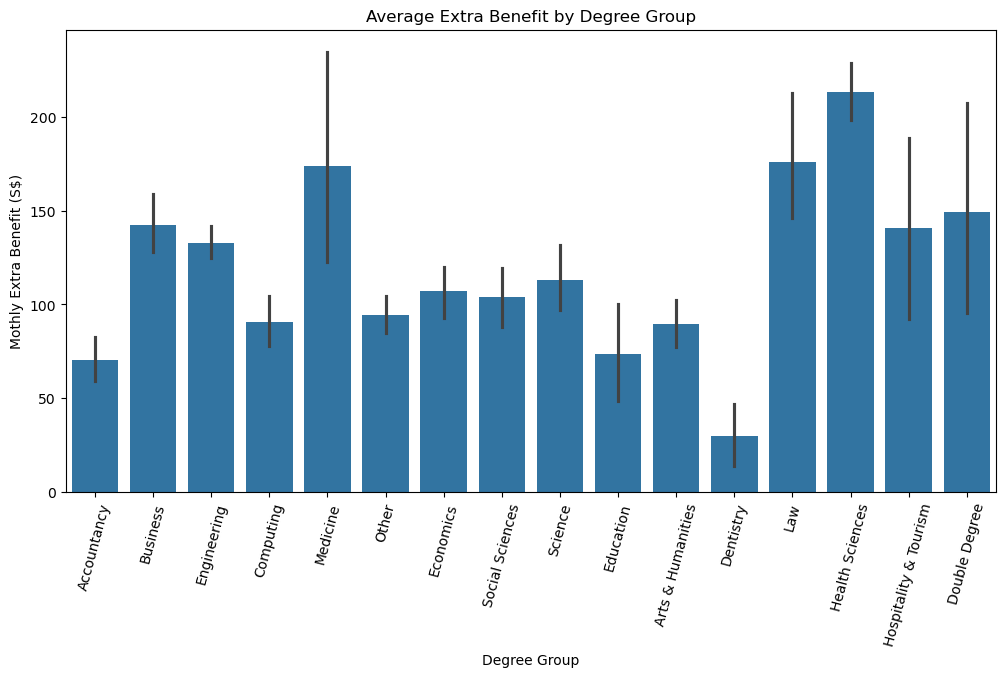

In [185]:
plt.figure(figsize=(12,6))
sns.barplot(data=ca2_df, x="degree_group", y="extra_benefit")
plt.xticks(rotation=75)
plt.title("Average Extra Benefit by Degree Group")
plt.ylabel("Mothly Extra Benefit (S$)")
plt.xlabel("Degree Group")
plt.show()

#### Reflection: Average Extra Benefit by Degree Group
This chart highlights how different degrees provide additional financial benefits beyond base salary.
Key insights:
- Medicine, Law, and Health Sciences show the highest extra benefits.
- Engineering, Business, and Computing offer moderate extras with some variable benefits.
- Accountancy and Dentistry show the lowest extra benefits, suggesting more standardized pay structures with fewer allowances.
- On average, a person can expect an additional benefit of $100 a month.

#### 3.2.3 Work Hour Distribution

We used a KDE plot to show how work hours per week are spread out for men and women. This makes it easy to see differences in patterns, like whether one group tends to work longer hours or if their distributions overlap. By looking at the shape of the data instead of just averages, we get a clearer view of workload and how it relates to gender and work–life balance.

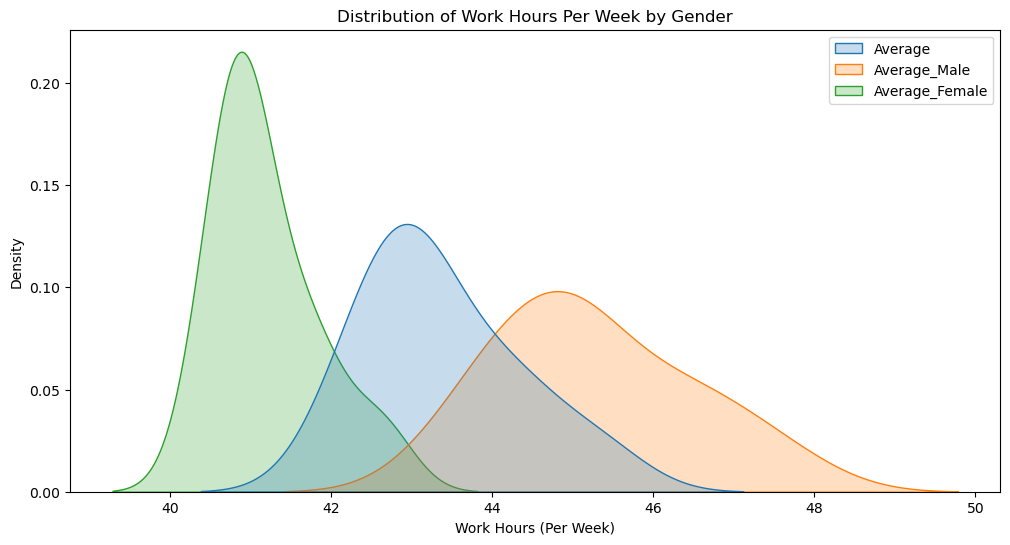

In [186]:
plt.figure(figsize=(12,6))
sns.kdeplot([mom_df['Average'], mom_df['Average_Male'], mom_df['Average_Female']], fill=True)
plt.title('Distribution of Work Hours Per Week by Gender')
plt.xlabel('Work Hours (Per Week)')
plt.show()

#### Reflection: Distribution of Work Hours
This chart highlights how the weekly work hours differentiates between genders.
Key insights:
- The peak density of female work hours lies at approximately 41 hours weekly.
- The peak density of male work hours lies at approximately 45 hours weekly.
- The difference of the average male work hours and female work hours may suggest a resulting difference in salary.
- On average, a person in the workforce works about 43 hours weekly.

#### 3.2.4 Work Hour Consistency

We used a line chart to show the average weekly work hours for men and women across different years because it makes trends over time easy to see. By plotting both groups together, we can directly compare how male and female work hours change year by year, whether the gap is widening or narrowing, and how consistent each group’s workload is. This connects directly to our study of gender differences, long‑term employment patterns, and work–life balance.

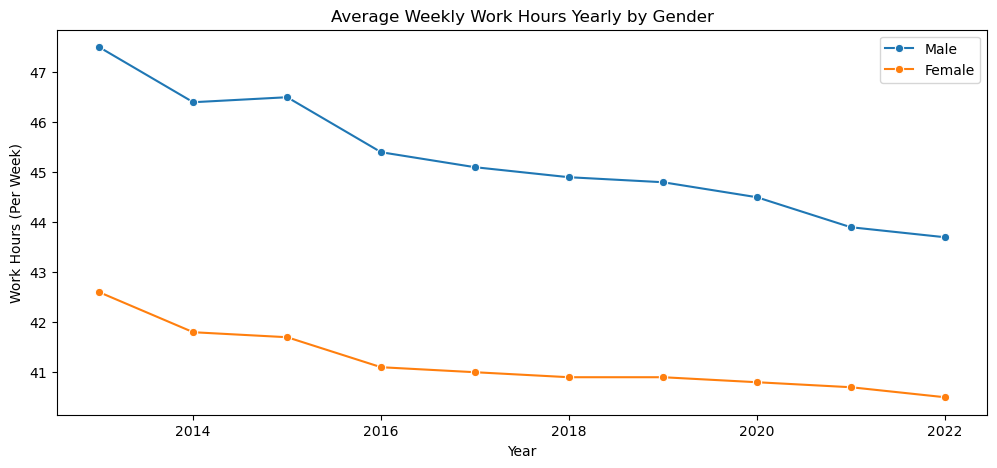

In [187]:
plt.figure(figsize=(12,5)) 
sns.lineplot(data=mom_df, x="Year", y="Average_Male", label="Male", marker="o") 
sns.lineplot(data=mom_df, x="Year", y="Average_Female", label="Female", marker="o") 
plt.title('Average Weekly Work Hours Yearly by Gender') 
plt.ylabel('Work Hours (Per Week)') 
plt.legend() 
plt.show()


#### Reflection: Average Weekly Work Hours by Gender
This chart highlights the trend of weekly work hours over the years between genders.
Key insights:
- There is a general downwards trend of weekly work hours for both genders.
- There is a bump in the otherwise general downwards trend between the years 2014 and 2015.
- The difference of weekly work hours for males and females seem to be getting smaller over the years.
- Based on the trend demonstrated by this visual, we should expect the average weekly work hours to continue decreasing.

#### 3.2.5 Employment Trend

We used a heatmap to show employment rates by gender across the years because it makes patterns and differences easy to spot at a glance. The color shading highlights where employment rates are higher or lower, while the annotations provide exact values for precision. This combination helps us quickly compare male and female employment outcomes over time and see how trends shift across the 2013–2022 period. It links directly to our study of gender, and long‑term employment patterns.

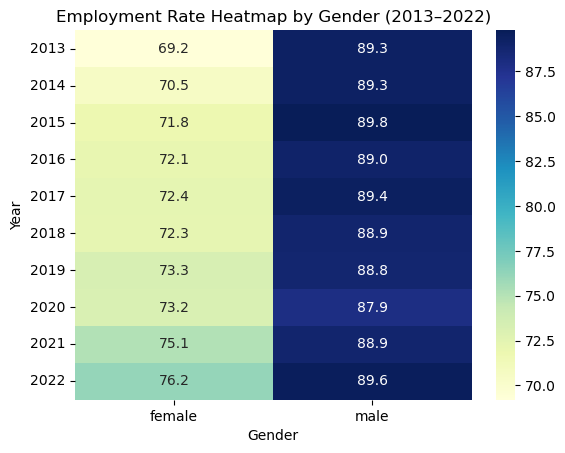

In [188]:
pivot = exl_scale_df.pivot(index="year", columns="sex", values="emp_rate")
sns.heatmap(pivot, annot=True, cmap="YlGnBu", fmt=".1f")
plt.yticks(rotation=0, fontsize=10)
plt.title("Employment Rate Heatmap by Gender (2013–2022)")
plt.ylabel("Year")
plt.xlabel("Gender")
plt.show()

#### Reflection: Employment Rate by Gender (2013–2022)
This chart highlights the employment rate patterns for males and females across the years.
Key insights:
- Male employment rates remain consistently high, hovering around 88–90% throughout the period.
- Female employment rates show a steady upward trend, rising from about 69% in 2013 to over 76% in 2022.
- The gap between male and female employment rates is narrowing, indicating progress toward greater gender parity in employment.
- Based on this visual, we can expect female employment rates to continue improving, while male rates remain stable.


#### 3.2.6 Relationship between Different Factors

We used a pairplot with regression lines to explore the relationships between employment rate, mean salary, and extra benefits. The scatter plots make it easy to see how these variables interact, while the regression lines highlight overall trends. We chose to use the mean salary because it reflects the overall average earnings across graduates and allows us to directly compare salary levels between groups. While the mean can be influenced by extreme values, it provides a useful measure of the general earning in the dataset. This visualization links directly to our study by showing how employment outcomes connect with salary levels and additional benefits, giving us both individual distributions and cross‑variable trends in one compact view.

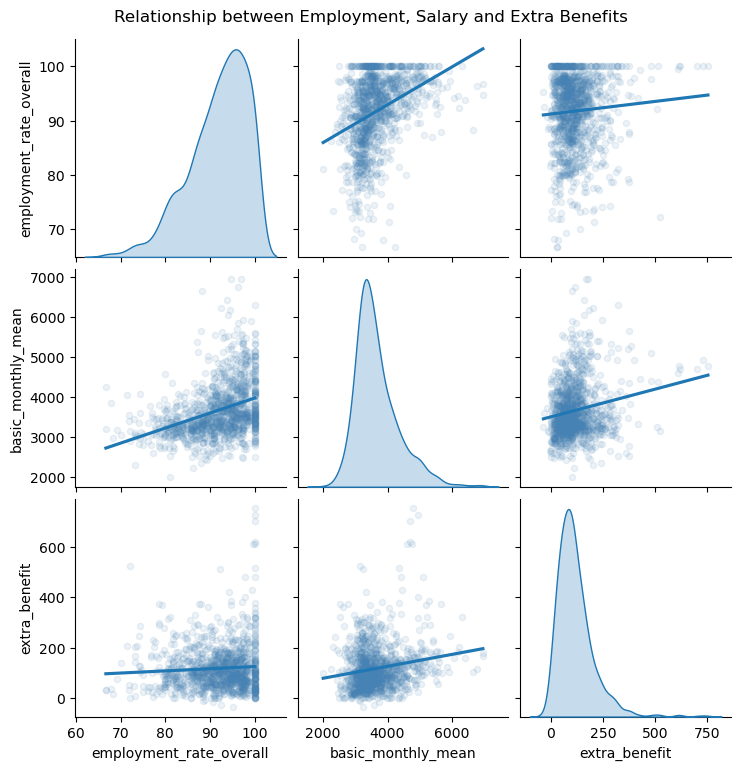

In [189]:
sns.pairplot(ca2_df,
             vars=["employment_rate_overall", 
                   "basic_monthly_mean", 
                   "extra_benefit"],
             diag_kind="kde",
             kind="reg",
             plot_kws={
                 "ci": None, 
                 "scatter_kws": {"alpha": 0.1, "s": 20, "color": "steelblue"} 
             }
             )

plt.suptitle("Relationship between Employment, Salary and Extra Benefits", y=1.02)
plt.show()

#### Reflection: Relationship Between Employment, Salary and Extra Benefits
This chart highlights how employment rate, average monthly salary, and extra benefits are connected, both individually and in relation to one another.  

- **Employment–Salary Relationship:** The scatterplots show a positive trend between employment rate and average monthly salary. Higher employment rates are generally associated with higher salaries which means that stronger job markets lead to better pay outcomes.  
- **Employment–Benefit Relationship:** Employment rate also shows a weak positive link with extra benefits. Eventhough employment improves, extra benefit packages tend to stay the same. 
- **Salary–Benefit Relationship:** Salary and extra benefits are positively related, with regression lines indicating that graduates who earn higher base salaries also receive more additional benefits.
- **Distributions of Features:** The diagonal plots show the distributions of each variable. Employment rate is clustered at higher values that indicate generally strong job markets. Salary distribution shows variation but centers around a clear average, while extra benefits is around $100
a month with some outliers.

**Overall:**  
This visualization provides a compact view of both distributions and cross-variable relationships. It shows that employment outcomes, salary levels, and extra benefits move together and shows the idea that stronger job markets are linked to better and more comprehensive work life.  


## 4. Overall Conclusion

### Sub‑Question 1: How do different degrees influence salary outcomes and extra benefits?  
- **Graphs used**: *Salary Distribution by Degree Group* and *Average Extra Benefit by Degree Group*.  
- **Findings**:  
  - Law, Dentistry, and Double Degree graduates earn the highest salaries with relatively stable distributions.  
  - Hospitality & Tourism graduates earn the lowest salaries, while popular choices like Engineering, Business, and Computing sit in the mid‑range and overall average is **SGD3500 per month**  
  - Medicine, Law, and Health Sciences provide the highest extra benefits (over **SGD150 per month**), while Accountancy and Dentistry show more standardized packages with fewer allowances. Overall average is **SGD100 per month**.  
- **Implication for job seekers**: Degree choice strongly shapes earning potential and benefits, with professional fields offering both higher pay and more extra benefits.  

---

### Sub‑Question 2: How does gender affect employment rates?  
- **Graph used**: *Employment Rate by Gender (2013–2022)*.  
- **Findings**:  
  - Male employment rates remain consistently high at **88–90%**.  
  - Female employment rates have steadily improved, rising from **69% in 2013** to over **76% in 2022**, narrowing the gender gap.  
- **Implication for job seekers**: Employment opportunities are strong across genders, with female graduates experiencing improving prospects and greater parity over time.  

---

### Sub‑Question 3: How does gender shape work‑life balance through differences in working hours?  
- **Graphs used**: *Distribution of Work Hours* and *Average Weekly Work Hours by Gender*.  
- **Findings**:  
  - Men work slightly longer hours (average **45 hours**) compared to women (**41 hours**), with the overall workforce averaging **43 hours weekly**.  
  - Both genders show a downward trend in weekly hours over time, with the gap between male and female hours narrowing.  
- **Implication for job seekers**: Work‑life balance is gradually improving, with reduced working hours and more equitable workloads between genders.  

---

### Cross‑Variable Insights  
- **Graph used**: *Relationship Between Employment, Salary and Extra Benefits*.  
- **Findings**:  
  - Employment rate and salary show a positive relationship: stronger job markets lead to better pay outcomes.  
  - Salary and extra benefits are also positively related, meaning higher base salaries often come with more allowances.  
  - Employment rate has only a weak link with benefits, suggesting benefit structures remain relatively stable even as employment improves.  
- **Implication for job seekers**: Stronger job markets not only increase the likelihood of employment but also improve salary outcomes, while benefits are more dependent on the type of degree and role.  

---

### Final Answer to Main Research Question  
**Main Question**: *What career outcomes can graduates expect in Singapore, based on their degree choice and gender?*  

- **Average career outcomes**: A graduate in Singapore can expect around **SGD3500 in monthly salary**, **SGD100 in monthly benefits**, an **employment rate above 85%**, and an average workload of **43 hours per week**, which is gradually decreasing.  
- **Degree choice** primarily influences salary and benefits, while **gender** shapes employment trends and work‑life balance.  
- **Interrelationships** show that stronger job markets are linked to higher salaries and high salary can link to more comprehensive benefits.
- **Overall guidance for job seekers**: Career outcomes are multi‑dimensional. Graduates should evaluate not only pay, but also benefits, employment opportunities, and lifestyle balance when making career decisions.  

---
---